In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.cluster import DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

columns = ["Income", "DTI", "LoanAmount", "CreditScore", "EmploymentLength", "IssueYear", "Default"]
df = pd.read_csv("../data/processed/loans_clean.csv", usecols=columns)

X_pca = np.load("../data/processed/X_pca.npy")
sample_idx = np.load("../data/processed/sample_idx.npy")
labels = np.load("../data/processed/labels_kmeans.npy")

try:
    with open("../models/segment_names.json") as file:
        names = {int(key): value for key, value in json.load(file).items()}
except FileNotFoundError:
    names = {}

df["Segment"] = labels
df["SegmentName"] = df["Segment"].map(lambda s: f"{s}: {names.get(s, 'Segment ' + str(s))}")

overall_rate = df["Default"].mean()
print("Portfolio default rate:", round(overall_rate, 3))

Portfolio default rate: 0.2


,loans,defaults,default_rate,ci_low,ci_high,vs_portfolio
SegmentName,,,,,,
1: Segment 1,286607,78669,0.2745,0.2729,0.2761,1.3739
4: Segment 4,266401,55626,0.2088,0.2073,0.2104,1.0451
0: Segment 0,345055,66134,0.1917,0.1904,0.1930,0.9593
3: Segment 3,293888,53951,0.1836,0.1822,0.1850,0.9189
2: Segment 2,155730,14869,0.0955,0.0940,0.0969,0.4779


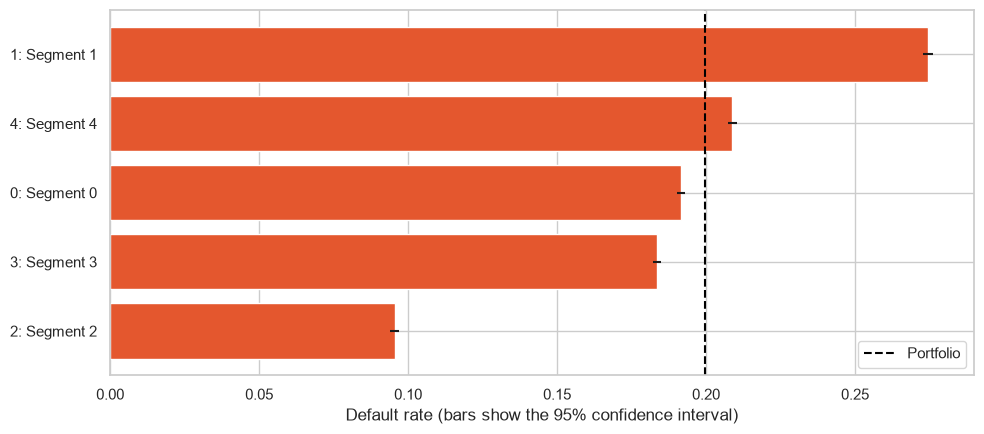

In [2]:
def wilson_interval(defaults, loans, z=1.96):
    """A 95% confidence interval for a proportion (the Wilson interval)."""
    p = defaults / loans
    centre = (p + z**2 / (2 * loans)) / (1 + z**2 / loans)
    margin = z * np.sqrt(p * (1 - p) / loans + z**2 / (4 * loans**2)) / (1 + z**2 / loans)
    return centre - margin, centre + margin


summary = df.groupby("SegmentName")["Default"].agg(loans="size", defaults="sum")
summary["default_rate"] = summary["defaults"] / summary["loans"]
summary["ci_low"], summary["ci_high"] = wilson_interval(summary["defaults"], summary["loans"])
summary["vs_portfolio"] = summary["default_rate"] / overall_rate
summary = summary.sort_values("default_rate", ascending=False)
display(summary.round(4))

order = summary.sort_values("default_rate").index
rates = summary.loc[order]
plt.figure(figsize=(10, 4.5))
plt.barh(order, rates["default_rate"],
         xerr=[rates["default_rate"] - rates["ci_low"], rates["ci_high"] - rates["default_rate"]],
         color="#E4572E")
plt.axvline(overall_rate, color="black", linestyle="--", label="Portfolio")
plt.xlabel("Default rate (bars show the 95% confidence interval)")
plt.legend()
plt.tight_layout()
plt.savefig("../docs/figures/21_default_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
table = pd.crosstab(df["Segment"], df["Default"])
chi2, p_value, dof, _ = chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (len(df) * (min(table.shape) - 1)))

print(f"Chi-square = {chi2:,.0f}, degrees of freedom = {dof}, p-value = {p_value:.3g}")
print(f"Cramer's V (effect size) = {cramers_v:.3f}")

Chi-square = 21,362, degrees of freedom = 4, p-value = 0
Cramer's V (effect size) = 0.126


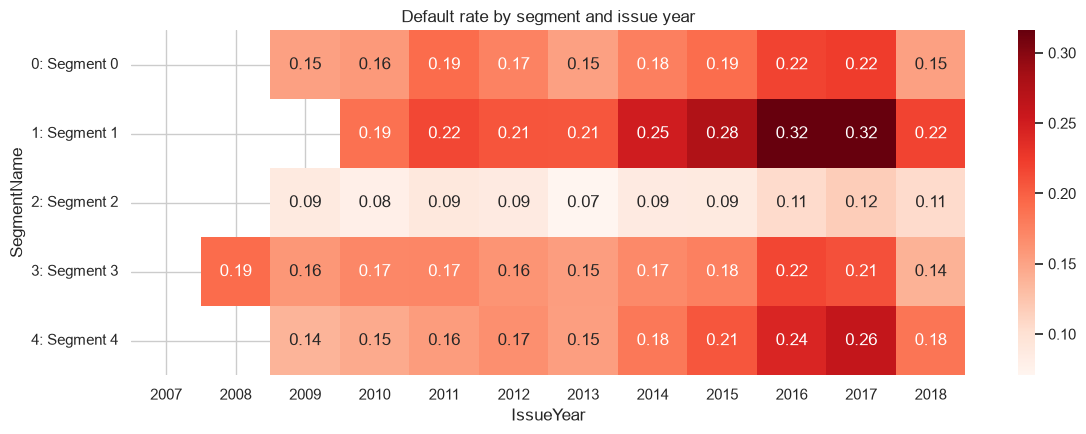

Rank of each segment in recent years (1 = highest default rate):


IssueYear,2014,2015,2016,2017,2018
SegmentName,,,,,
0: Segment 0,3.0,3.0,3.0,3.0,3.0
1: Segment 1,1.0,1.0,1.0,1.0,1.0
2: Segment 2,5.0,5.0,5.0,5.0,5.0
3: Segment 3,4.0,4.0,4.0,4.0,4.0
4: Segment 4,2.0,2.0,2.0,2.0,2.0


In [4]:
by_year = df.pivot_table(index="SegmentName", columns="IssueYear", values="Default", aggfunc="mean")
counts = df.pivot_table(index="SegmentName", columns="IssueYear", values="Default", aggfunc="size")
by_year = by_year.where(counts >= 500)            # hide cells with too few loans to trust

plt.figure(figsize=(12, 4.5))
sns.heatmap(by_year, annot=True, fmt=".2f", cmap="Reds")
plt.title("Default rate by segment and issue year")
plt.tight_layout()
plt.savefig("../docs/figures/22_default_segment_year.png", dpi=150, bbox_inches="tight")
plt.show()

print("Rank of each segment in recent years (1 = highest default rate):")
by_year.rank(ascending=False).round(0).iloc[:, -5:]

In [5]:
def adjusted_default_rate(frame, years):
    """Default rate each segment would have if it had the same issue-year mix as the whole portfolio."""
    subset = frame[frame["IssueYear"].isin(years)]
    cells = subset.groupby(["SegmentName", "IssueYear"])["Default"].agg(rate="mean").reset_index()
    cells["weight"] = cells["IssueYear"].map(subset["IssueYear"].value_counts(normalize=True))
    cells["part"] = cells["rate"] * cells["weight"]
    totals = cells.groupby("SegmentName")[["part", "weight"]].sum()
    return totals["part"] / totals["weight"]


adjusted = pd.DataFrame({
    "raw_rate": summary["default_rate"],
    "adjusted_all_years": adjusted_default_rate(df, sorted(df["IssueYear"].unique())),
    "adjusted_2012_2016": adjusted_default_rate(df, range(2012, 2017)),
}).sort_values("raw_rate", ascending=False)
adjusted.round(4)

,raw_rate,adjusted_all_years,adjusted_2012_2016
SegmentName,,,
1: Segment 1,0.2745,0.2716,0.2698
4: Segment 4,0.2088,0.2079,0.2028
0: Segment 0,0.1917,0.1924,0.1899
3: Segment 3,0.1836,0.1839,0.1825
2: Segment 2,0.0955,0.0940,0.0900


In [6]:
def compare_segments(first, second):
    """Difference in default rate (percentage points) with a 95% interval."""
    a = df[df["Segment"] == first]["Default"]
    b = df[df["Segment"] == second]["Default"]
    gap = a.mean() - b.mean()
    error = 1.96 * np.sqrt(a.mean() * (1 - a.mean()) / len(a) + b.mean() * (1 - b.mean()) / len(b))
    return gap * 100, (gap - error) * 100, (gap + error) * 100


FIRST_SEGMENT, SECOND_SEGMENT = 0, 4         # the pair that differ mainly in employment tenure

gap, low, high = compare_segments(FIRST_SEGMENT, SECOND_SEGMENT)
print(f"Segment {FIRST_SEGMENT} minus segment {SECOND_SEGMENT}: {gap:+.2f} percentage points "
      f"(95% interval {low:+.2f} to {high:+.2f})")

Segment 0 minus segment 4: -1.71 percentage points (95% interval -1.92 to -1.51)


In [7]:
isolation = IsolationForest(n_estimators=100, random_state=42, n_jobs=-1).fit(X_pca)
scores = isolation.score_samples(X_pca)               # lower = more unusual
threshold = np.quantile(scores, 0.01)                 # flag the most unusual 1%
df["IF_Anomaly"] = scores <= threshold

print("Flagged as unusual:", f"{df['IF_Anomaly'].sum():,}", "of", f"{len(df):,}")

Flagged as unusual: 13,477 of 1,347,681


In [8]:
X_db = X_pca[sample_idx]                    # the same 20,000 borrowers as before
MIN_SAMPLES = 10
k_dist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_db).kneighbors(X_db)[0][:, -1])

db_labels = DBSCAN(eps=float(np.quantile(k_dist, 0.95)), min_samples=MIN_SAMPLES).fit_predict(X_db)
db_noise = db_labels == -1
if_in_sample = df["IF_Anomaly"].to_numpy()[sample_idx]

print("DBSCAN noise points:", db_noise.sum())
print("Isolation Forest flags in the same 20,000:", if_in_sample.sum())
print("Flagged by both:", (db_noise & if_in_sample).sum())

DBSCAN noise points: 284
Isolation Forest flags in the same 20,000: 221
Flagged by both: 117


In [9]:
numeric = ["Income", "LoanAmount", "DTI", "CreditScore", "EmploymentLength"]
display(df.groupby("IF_Anomaly")[numeric].median().round(1))

anomaly_summary = df.groupby("IF_Anomaly")["Default"].agg(loans="size", default_rate="mean")
anomaly_summary["ci_low"], anomaly_summary["ci_high"] = wilson_interval(
    df.groupby("IF_Anomaly")["Default"].sum(), anomaly_summary["loans"])
display(anomaly_summary.round(4))

print("Share of each segment flagged unusual (%):")
print((df.groupby("SegmentName")["IF_Anomaly"].mean() * 100).round(2))

print("\nData-quality anomalies (DTI above 100, set to missing in preprocessing):", (df["DTI"] > 100).sum())

,Income,LoanAmount,DTI,CreditScore,EmploymentLength
IF_Anomaly,,,,,
False,65000.0,12000.0,17.7,692.0,6.0
True,61848.0,4400.0,11.0,782.0,3.0


,loans,default_rate,ci_low,ci_high
IF_Anomaly,,,,
False,1334204,0.2005,0.1999,0.2012
True,13477,0.1249,0.1194,0.1306


Share of each segment flagged unusual (%):
SegmentName
0: Segment 0    0.05
1: Segment 1    0.38
2: Segment 2    4.96
3: Segment 3    1.22
4: Segment 4    0.34
Name: IF_Anomaly, dtype: float64

Data-quality anomalies (DTI above 100, set to missing in preprocessing): 533


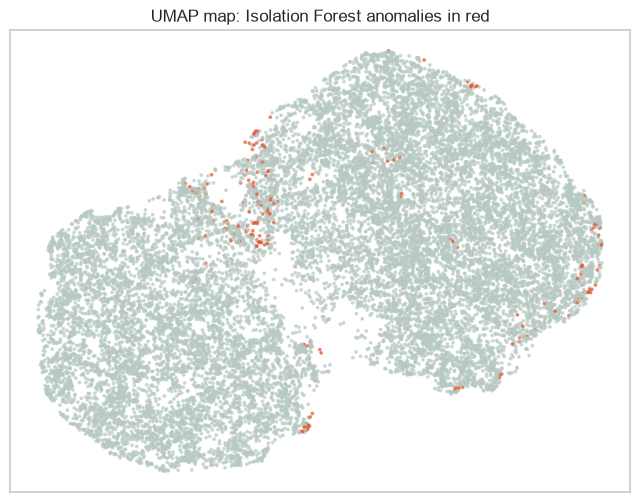

In [10]:
umap_embedding = np.load("../data/processed/umap_embedding.npy")
colors = np.where(if_in_sample, "#E4572E", "#B7C9C2")

plt.figure(figsize=(8, 6))
plt.scatter(umap_embedding[:, 0], umap_embedding[:, 1], c=colors, s=3, alpha=0.6)
plt.title("UMAP map: Isolation Forest anomalies in red")
plt.xticks([])
plt.yticks([])
plt.savefig("../docs/figures/23_anomalies_umap.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
summary.round(4).to_csv("../models/default_by_segment.csv")
adjusted.round(4).to_csv("../models/default_adjusted_by_segment.csv")
by_year.round(4).to_csv("../models/default_by_segment_year.csv")
np.save("../data/processed/anomaly_flags.npy", df["IF_Anomaly"].to_numpy())

joblib.dump(isolation, "../models/isolation_forest.joblib")
with open("../models/anomaly_info.json", "w") as file:
    json.dump({"score_threshold": float(threshold), "flagged_share": 0.01,
               "chi2": float(chi2), "cramers_v": float(cramers_v)}, file, indent=2)
print("Saved")

Saved
